In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,ConfusionMatrixDisplay)

In [2]:
# Load the loan approval dataset
df = pd.read_csv("purchase_data.csv")
# Display first five rows
df.head()

,Age,Salary,Ad_Clicks,Time_On_Site,Purchased
0,56,81476,13,3.4,1
1,46,64811,2,7.4,0
2,32,56208,4,20.8,0
3,25,40150,4,3.2,0
4,38,91180,18,25.7,1


In [4]:
# Check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Age           500 non-null    int64  
 1   Salary        500 non-null    int64  
 2   Ad_Clicks     500 non-null    int64  
 3   Time_On_Site  500 non-null    float64
 4   Purchased     500 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 19.7 KB


In [5]:
# Check dataset dimensions
print(df.shape)

(500, 5)


In [6]:
# Check for missing values
print(df.isnull().sum())

Age             0
Salary          0
Ad_Clicks       0
Time_On_Site    0
Purchased       0
dtype: int64


In [11]:
# Check Purchased categories
print(df['Purchased'].unique())

[1 0]


In [15]:
# Select independent variables
X = df[['Age', 'Salary', 'Ad_Clicks', 'Time_On_Site']]

# Select dependent variable
y = df['Purchased']

# Display first five rows
X.head()

,Age,Salary,Ad_Clicks,Time_On_Site
0,56,81476,13,3.4
1,46,64811,2,7.4
2,32,56208,4,20.8
3,25,40150,4,3.2
4,38,91180,18,25.7


In [16]:
# Convert categorical variables into dummy variables
X = pd.get_dummies(X,columns=['Age', 'Salary'],drop_first=True,dtype=int)
# Display updated data
X.head()

,Ad_Clicks,Time_On_Site,Age_19,Age_20,Age_21,Age_22,Age_23,Age_24,Age_25,Age_26,...,Salary_116573,Salary_117007,Salary_117203,Salary_117239,Salary_117579,Salary_117829,Salary_118142,Salary_119518,Salary_119657,Salary_119835
0,13,3.4,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,7.4,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,20.8,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,3.2,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,18,25.7,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [17]:
# Convert Purchased into numerical values
y = y.map({'Approved': 1,'Rejected': 0})

# Display first five values
y.head()

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: Purchased, dtype: float64

In [19]:
# Check unique Purchased values
print(df['Purchased'].unique())


[1 0]


In [20]:
X =df.drop('Purchased', axis=1)
y =df['Purchased']
print(y.head())

0    1
1    0
2    0
3    0
4    1
Name: Purchased, dtype: int64


In [21]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)
# Display dataset shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (400, 4)
X_test shape: (100, 4)
y_train shape: (400,)
y_test shape: (100,)


In [22]:
# Create Logistic Regression model
model = LogisticRegression(max_iter=1000)
# Train the model
model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [23]:
# Predict Purchased
y_pred = model.predict(X_test)

# Compare actual and predicted results
comparison = pd.DataFrame({
    'Actual Purchase': y_test.values,
    'Predicted Purchase': y_pred
})

# Display first 10 results
comparison.head(10)

,Actual Purchase,Predicted Purchase
0,1,0
1,1,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,0,1
8,0,1
9,1,1


In [24]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=['Rejected', 'Approved']
)

print("Accuracy:", accuracy)
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", report)

Accuracy: 0.76

Confusion Matrix:
 [[32  9]
 [15 44]]

Classification Report:
               precision    recall  f1-score   support

    Rejected       0.68      0.78      0.73        41
    Approved       0.83      0.75      0.79        59

    accuracy                           0.76       100
   macro avg       0.76      0.76      0.76       100
weighted avg       0.77      0.76      0.76       100



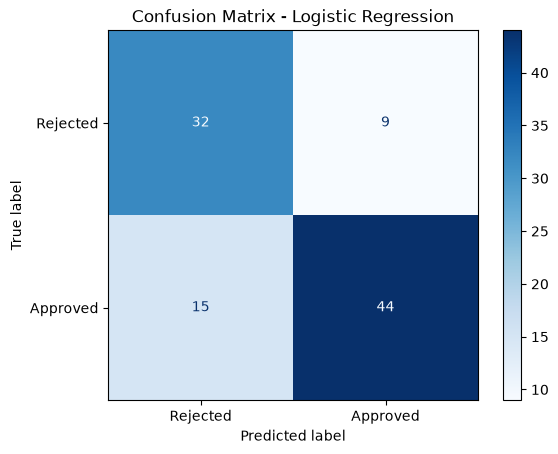

In [25]:
# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Rejected', 'Approved']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()